# Entrega proyecto: clasificación

Integrantes Team-12:
* CAMILO MUNOZ HALIFA
* DIEGO ALEJANDRO FIGUEREDO SALAMANCA
* FABIAN ANDRES GULLAVAN VERA
* SILVIA CARDENAS SANTOS

# 1. Selección de modelo de clasificación — UniBank

* **Propósito**

Comparar **tres clasificadores** para predecir `Subscription`. La métrica de la competencia es ROC-AUC; por eso esa será la métrica principal para ordenar los candidatos.

Se seleccionaron regresión logística, análisis discriminante lineal (LDA) y árbol de decisión. No obstante, en otra exploración se encontraron tres modelos (Random Forest, Extra Trees e HistGradientBoosting) que sobresalieron.

* **Criterio de selección**

1. Comparar los tres modelos con validación cruzada estratificada de cinco pliegues, usando las mismas divisiones.
2. Ordenar por ROC-AUC medio; reportar también Average Precision y métricas al umbral 0,5 como información complementaria.
3. Revisar la interpretabilidad y los criterios para la selección del modelo.

La desviación estándar reportada es la variación entre pliegues, no un intervalo de confianza. El archivo de prueba de Kaggle no se usa para elegir ni ajustar el modelo.

## 1.1 Preparar entorno y cargar los datos

Los archivos de la competencia se descargan con `kagglehub`, usando `KAGGLE_API_TOKEN` del archivo `.env`, igual que en el notebook de regresion. Se identifica el CSV de entrenamiento y, si esta disponible, el de prueba.


In [12]:
import os
from pathlib import Path

import kagglehub
import numpy as np
import pandas as pd
from dotenv import load_dotenv

env_path = Path.cwd() / ".env"
if not env_path.is_file():
    raise FileNotFoundError("No se encontro .env")
load_dotenv(env_path, override=True)
if not os.environ.get("KAGGLE_API_TOKEN", "").strip():
    raise ValueError("Falta KAGGLE_API_TOKEN en el archivo .env.")

data_dir = Path(kagglehub.competition_download("mae-competencia-clasificacion-202620"))
print("Path to competition files:", data_dir)
csv_files = [file.name for file in data_dir.iterdir() if file.suffix.lower() == '.csv']
train_name = next((name for name in csv_files if 'train' in name.lower()), None)
if train_name is None:
    raise FileNotFoundError("No se encontro el archivo Train bank.csv en la descarga.")
train = pd.read_csv(data_dir / train_name)

test_name = next((name for name in csv_files if 'test' in name.lower()), None)
if test_name:
    test = pd.read_csv(data_dir / test_name)
else:
    test = pd.DataFrame(columns=train.drop(columns=['Subscription'], errors='ignore').columns)

TARGET = 'Subscription'
ID = 'id'
if TARGET not in train.columns:
    raise KeyError(f"No se encontró la variable objetivo '{TARGET}'.")
y = train[TARGET].astype(int)
X = train.drop(columns=[TARGET, ID], errors='ignore')
print('Entrenamiento:', train_name, train.shape)
print('Prueba Kaggle:', test_name if test_name else 'no cargada', test.shape)
print('Distribución de Subscription:')
print(y.value_counts().sort_index())

ValueError: time data 'Mon, 19 Oct 2026 03:06:43 GMT' does not match format '%a, %d %b %Y %H:%M:%S %Z'

## 1.2 Perfil de calidad y clase objetivo

In [ ]:
perfil = pd.DataFrame({
    'Conjunto': ['Entrenamiento', 'Prueba Kaggle'],
    'Filas': [len(train), len(test)],
    'Columnas': [train.shape[1], test.shape[1]],
    'Valores faltantes': [int(train.isna().sum().sum()), int(test.isna().sum().sum())],
    'Filas duplicadas': [int(train.duplicated().sum()), int(test.duplicated().sum())],
})
display(perfil)
display(pd.DataFrame({
    'Subscription': y.value_counts().sort_index().index,
    'Casos': y.value_counts().sort_index().values,
    'Proporción': y.value_counts(normalize=True).sort_index().values,
}))

,Conjunto,Filas,Columnas,Valores faltantes,Filas duplicadas
0,Entrenamiento,31648,18,0,0
1,Prueba Kaggle,13563,17,0,0


,Subscription,Casos,Proporción
0,0,27951,0.883184
1,1,3697,0.116816


## 1.3 Preprocesamiento y tres clasificadores

La imputación y la codificación se ajustan dentro de cada pliegue para evitar filtración entre entrenamiento y validación. Las variables numéricas se imputan con mediana y se estandarizan; las categóricas se imputan con la moda y se convierten a indicadores. El árbol no requiere escalamiento, pero se mantiene el mismo preprocesamiento categórico para que todos reciban las mismas variables.

**Configuraciones comparadas:**

- **Regresión logística:** `class_weight='balanced'`, que compensa el desbalance. En la exploración previa, el peso balanceado dio AUC ≈ 0,9061; los pesos 1:8 quedaron prácticamente iguales.
- **LDA:** `solver='lsqr'` y `shrinkage='auto'`, configuración ya comparada en el notebook anterior.
- **Árbol de decisión:** criterio Gini, `max_depth=10`, `min_samples_leaf=20` y clase balanceada. La profundidad limita la complejidad y el tamaño mínimo de hoja ayuda a evitar particiones con muy pocos casos.

Las métricas de precisión, recall, F1 y balanced accuracy usan el umbral predeterminado 0,5. Se comparan las probabilidades con ROC-AUC, no las etiquetas 0/1.

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import make_scorer, precision_score, recall_score, f1_score, balanced_accuracy_score
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier
import matplotlib.pyplot as plt
import seaborn as sns

numeric_cols = X.select_dtypes(include=np.number).columns.tolist()
categorical_cols = [c for c in X.columns if c not in numeric_cols]

def make_preprocessor(columns):
    nums = [c for c in numeric_cols if c in columns]
    cats = [c for c in categorical_cols if c in columns]
    try:
        encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
    except TypeError:  # Compatibilidad con versiones anteriores de scikit-learn en Colab
        encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)
    return ColumnTransformer([
        ('numeric', Pipeline([
            ('imputer', SimpleImputer(strategy='median')),
            ('scale', StandardScaler())
        ]), nums),
        ('categorical', Pipeline([
            ('imputer', SimpleImputer(strategy='most_frequent')),
            ('onehot', encoder)
        ]), cats),
    ], remainder='drop')

model_specs = [
    ('Regresión logística balanceada', LogisticRegression(
        max_iter=2000, C=1.0, solver='liblinear', class_weight='balanced'
    )),
    ('LDA con shrinkage automático', LinearDiscriminantAnalysis(
        solver='lsqr', shrinkage='auto'
    )),
    ('Árbol de decisión balanceado', DecisionTreeClassifier(
        criterion='gini', max_depth=10, min_samples_leaf=20,
        class_weight='balanced', random_state=2026
    )),
]

scoring = {
    'auc': 'roc_auc',
    'average_precision': 'average_precision',
    'precision': make_scorer(precision_score, zero_division=0),
    'recall': make_scorer(recall_score, zero_division=0),
    'f1': make_scorer(f1_score, zero_division=0),
    'balanced_accuracy': make_scorer(balanced_accuracy_score),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)
print('Modelos que se evaluarán:', len(model_specs))
print('Pliegues por modelo:', cv.n_splits)

Modelos que se evaluarán: 3
Pliegues por modelo: 5


## 1.4 Evaluar con validación cruzada

Esta celda calcula la media y la desviación estándar de cada métrica sobre cinco pliegues. Ejecute las celdas en orden para regenerar los resultados.

In [ ]:
rows = []
fold_results = []
for name, estimator in model_specs:
    pipeline = Pipeline([
        ('prep', make_preprocessor(list(X.columns))),
        ('model', estimator),
    ])
    scores = cross_validate(
        pipeline, X, y, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False, error_score='raise'
    )
    row = {'modelo': name}
    for metric in scoring:
        values = scores['test_' + metric]
        row[metric + '_media'] = float(np.mean(values))
        row[metric + '_sd'] = float(np.std(values, ddof=1))
    rows.append(row)
    for fold in range(cv.n_splits):
        fold_results.append({
            'modelo': name, 'pliegue': fold + 1,
            **{metric: float(scores['test_' + metric][fold]) for metric in scoring}
        })

resultados = pd.DataFrame(rows).sort_values('auc_media', ascending=False).reset_index(drop=True)
resultados_por_pliegue = pd.DataFrame(fold_results)
display(resultados.round(4))

,modelo,auc_media,auc_sd,average_precision_media,average_precision_sd,precision_media,precision_sd,recall_media,recall_sd,f1_media,f1_sd,balanced_accuracy_media,balanced_accuracy_sd
0,Regresión logística balanceada,0.9061,0.0037,0.5411,0.0091,0.4102,0.0123,0.8136,0.0119,0.5453,0.0113,0.8294,0.0063
1,LDA con shrinkage automático,0.9034,0.0042,0.5458,0.0154,0.6029,0.0177,0.4276,0.0091,0.5003,0.0098,0.6952,0.0047
2,Árbol de decisión balanceado,0.8881,0.0091,0.5187,0.0122,0.3751,0.0173,0.8483,0.0192,0.5199,0.0156,0.8304,0.0082


## 1.5 Gráficas para comparar los modelos

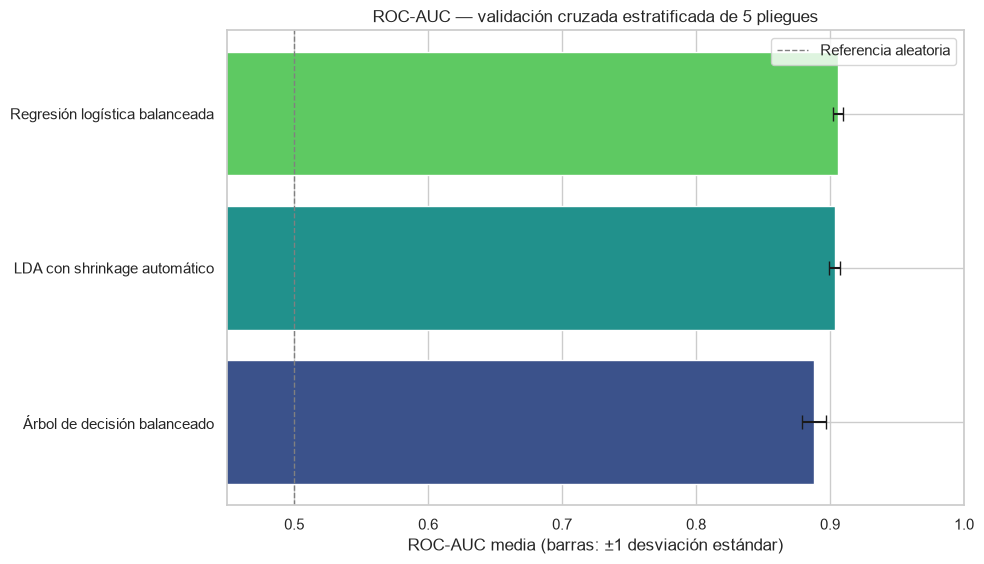

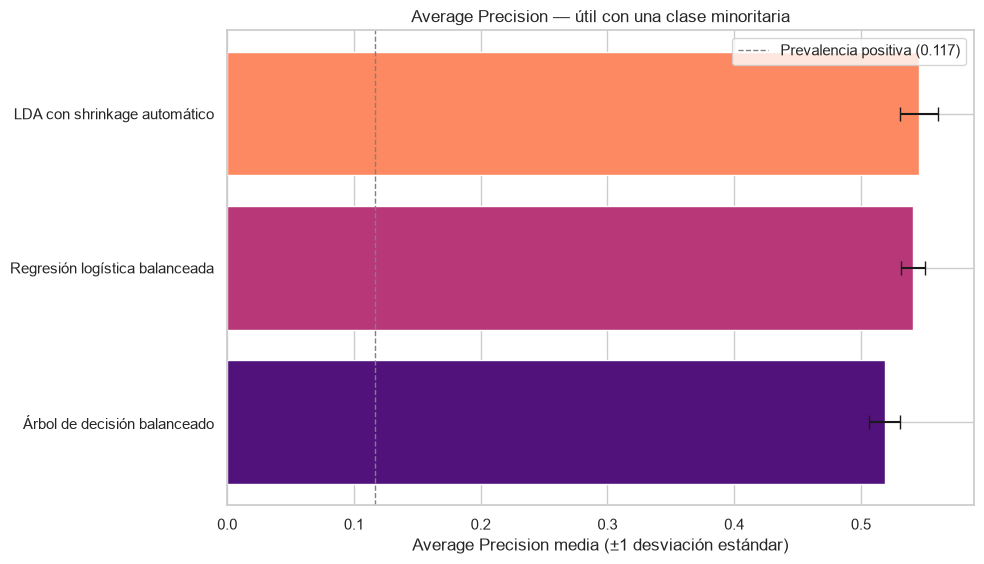

In [ ]:
sns.set_theme(style='whitegrid', context='notebook')
orden = resultados.sort_values('auc_media')
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(orden.modelo, orden.auc_media, xerr=orden.auc_sd,
        color=sns.color_palette('viridis', len(orden)), capsize=5)
ax.axvline(0.5, color='gray', linestyle='--', linewidth=1, label='Referencia aleatoria')
ax.set_xlim(0.45, 1.0)
ax.set_xlabel('ROC-AUC media (barras: ±1 desviación estándar)')
ax.set_title('ROC-AUC — validación cruzada estratificada de 5 pliegues')
ax.legend()
plt.tight_layout()
plt.show()

orden_ap = resultados.sort_values('average_precision_media')
fig, ax = plt.subplots(figsize=(10, 5.8))
ax.barh(orden_ap.modelo, orden_ap.average_precision_media,
        xerr=orden_ap.average_precision_sd,
        color=sns.color_palette('magma', len(orden_ap)), capsize=5)
ax.axvline(y.mean(), color='gray', linestyle='--', linewidth=1,
           label=f'Prevalencia positiva ({y.mean():.3f})')
ax.set_xlabel('Average Precision media (±1 desviación estándar)')
ax.set_title('Average Precision — útil con una clase minoritaria')
ax.legend()
plt.tight_layout()
plt.show()

## 1.6 Lectura de la corrida incluida y recomendación preliminar

En esta comparación, la regresión logística balanceada conserva el mejor AUC de los tres candidatos. LDA queda muy cerca en AUC y ofrece una formulación estadística distinta; el árbol de decisión ofrece reglas más intuitivas, pero su desempeño depende de la profundidad y puede perder capacidad de ordenamiento.

La tabla siguiente recoge los valores de la corrida reproducible con los archivos del grupo. Los resultados pueden variar levemente con la versión de scikit-learn o la configuración de ejecución.

In [ ]:
# Tabla de la corrida incluida; al ejecutar la sección 4 se recalcula `resultados`.
cols = ['modelo', 'auc_media', 'auc_sd', 'average_precision_media',
        'precision_media', 'recall_media', 'f1_media', 'balanced_accuracy_media']
display(resultados[cols].round(4))

,modelo,auc_media,auc_sd,average_precision_media,precision_media,recall_media,f1_media,balanced_accuracy_media
0,Regresión logística balanceada,0.9061,0.0037,0.5411,0.4102,0.8136,0.5453,0.8294
1,LDA con shrinkage automático,0.9034,0.0042,0.5458,0.6029,0.4276,0.5003,0.6952
2,Árbol de decisión balanceado,0.8881,0.0091,0.5187,0.3751,0.8483,0.5199,0.8304


* **Resumen:**
Se seleccionó preliminarmente la regresión logística balanceada porque obtuvo el mayor ROC-AUC promedio en validación cruzada estratificada de cinco pliegues entre las tres configuraciones evaluadas. Su ventaja frente a LDA fue pequeña; por ello, se mantiene como el modelo principal, sin afirmar una superioridad concluyente.

# 2. Estimación de los parámetros del modelo


## 2.1 Metodo de estimacion y alcance

Partiendo de la **regresion logistica balanceada** escogida en la seccion 1, con las mismas variables, imputacion, estandarizacion, indicadores, `C=1.0` y `solver='liblinear'`. Una vez comparados los candidatos por validacion cruzada, se reajusta esta configuracion con todo `X, y` para estimar sus parametros definitivos. El archivo de prueba no interviene en la estimacion.

El modelo expresa linealmente el logaritmo de los odds:

$$\eta_i=\beta_0+\sum_{j=1}^{k}\beta_j z_{ij},\qquad p_i=\frac{1}{1+e^{-\eta_i}}.$$

Aqui $z_{ij}$ es el predictor transformado. La clase usa maxima verosimilitud; la configuracion seleccionada emplea **log-verosimilitud ponderada y penalizacion L2**. Los pesos de clase son $w_c=n/(2n_c)$ y la contribucion de cada observacion es $w_{y_i}[y_i\log(p_i)+(1-y_i)\log(1-p_i)]$. `C` controla inversamente la intensidad de regularizacion; con `liblinear` tambien se penaliza el intercepto sintetico. Por tanto, los coeficientes no son estimadores de maxima verosimilitud ordinaria sin penalizacion.

In [ ]:
from sklearn.base import clone
from sklearn.exceptions import ConvergenceWarning
from scipy.special import expit
import warnings

# Recuperar exactamente la configuracion seleccionada, sin modificar model_specs.
nombre_modelo_final, especificacion_final = next(
    (nombre, estimador) for nombre, estimador in model_specs
    if isinstance(estimador, LogisticRegression)
)
modelo_final = Pipeline([
    ('prep', make_preprocessor(list(X.columns))),
    ('model', clone(especificacion_final)),
])
with warnings.catch_warnings(record=True) as avisos_ajuste:
    warnings.simplefilter('always', ConvergenceWarning)
    modelo_final.fit(X, y)
if any(issubclass(aviso.category, ConvergenceWarning) for aviso in avisos_ajuste):
    raise RuntimeError('El ajuste no convergio; revisar antes de interpretar los parametros.')

preprocesador_final = modelo_final.named_steps['prep']
logistica_final = modelo_final.named_steps['model']
nombres_parametros = preprocesador_final.get_feature_names_out()
beta_transformado = logistica_final.coef_[0]
intercepto_transformado = float(logistica_final.intercept_[0])
assert np.array_equal(logistica_final.classes_, [0, 1])

pesos_clase = len(y) / (2 * y.value_counts().sort_index())
print('Modelo:', nombre_modelo_final)
print('Observaciones:', len(y))
print('Coeficientes e intercepto:', len(beta_transformado) + 1)
print('Iteraciones:', logistica_final.n_iter_.tolist())
print('Pesos por clase:', pesos_clase.to_dict())
tabla_parametros = pd.DataFrame({
    'Parametro': ['Intercepto'] + list(nombres_parametros),
    'Coeficiente': np.r_[intercepto_transformado, beta_transformado],
})
display(tabla_parametros.round(6))

Modelo: Regresión logística balanceada
Observaciones: 31648
Coeficientes e intercepto: 52
Iteraciones: [6]
Pesos por clase: {0: 0.5661335909269793, 1: 4.280227211252367}


,Parametro,Coeficiente
0,Intercepto,-0.029825
1,numeric__Age,0.033714
2,numeric__Balance..euros.,0.070065
3,numeric__Last.Contact.Day,0.022712
4,numeric__Last.Contact.Duration,1.470205
5,numeric__Campaign,-0.324101
6,numeric__Pdays,0.010707
7,numeric__Previous,0.059227
8,categorical__Job_admin.,0.194121
9,categorical__Job_blue-collar,-0.158789


## 2.2 Parametros en unidades originales y contrastes entre categorias

Los coeficientes numericos anteriores corresponden a un aumento de una desviacion estandar. Se dividen por la escala de `StandardScaler` y se corrige el intercepto para expresar la misma ecuacion en unidades originales (despues de imputar).

Se conservaron todos los indicadores categoricos porque asi se comparo el modelo. Para interpretar una categoria frente a otra, se toma como referencia el primer nivel del codificador y se calcula la diferencia entre ambos coeficientes. Se suma al intercepto el coeficiente de cada referencia. Esta es una reexpresion exacta del ajuste, sin volver a estimar ni cambiar predicciones.

En la tabla, `exp(Coeficiente)` es el **odds ratio** por unidad numerica o frente a la categoria de referencia, manteniendo constantes los demas predictores. No es un cambio porcentual directo de la probabilidad ni demuestra causalidad. La ponderacion de clases tampoco garantiza probabilidades calibradas a la prevalencia original. No se reportan p-values ni intervalos clasicos para estos coeficientes penalizados.


In [ ]:
beta_original = beta_transformado.copy()
intercepto_original = intercepto_transformado
filas_parametros = []
if numeric_cols:
    escalador_final = preprocesador_final.named_transformers_['numeric'].named_steps['scale']
    cantidad_numericas = len(numeric_cols)
    beta_original[:cantidad_numericas] /= escalador_final.scale_
    intercepto_original -= float(np.dot(beta_original[:cantidad_numericas], escalador_final.mean_))
    for columna, coeficiente in zip(numeric_cols, beta_original[:cantidad_numericas]):
        filas_parametros.append({'Termino': columna, 'Comparacion': 'Por una unidad adicional',
                                 'Coeficiente': coeficiente})
else:
    cantidad_numericas = 0

referencias_categoricas = []
intercepto_referencia = intercepto_original
posicion = cantidad_numericas
if categorical_cols:
    codificador_final = preprocesador_final.named_transformers_['categorical'].named_steps['onehot']
    for columna, niveles in zip(categorical_cols, codificador_final.categories_):
        coeficientes = beta_original[posicion:posicion + len(niveles)]
        referencia = niveles[0]
        intercepto_referencia += float(coeficientes[0])
        referencias_categoricas.append({'Variable': columna, 'Referencia': referencia})
        for nivel, coeficiente in zip(niveles[1:], coeficientes[1:]):
            filas_parametros.append({'Termino': f'{columna}={nivel}',
                                     'Comparacion': f'Frente a {referencia}',
                                     'Coeficiente': float(coeficiente - coeficientes[0])})
        posicion += len(niveles)

tabla_parametros_originales = pd.DataFrame(filas_parametros)
tabla_parametros_originales['Odds ratio'] = np.exp(tabla_parametros_originales['Coeficiente'])
print(f'Intercepto con categorias de referencia: {intercepto_referencia:.6f}')
print('El intercepto corresponde a numericas iguales a cero y categorias de referencia; puede ser un perfil poco realista.')
display(pd.DataFrame(referencias_categoricas))
display(tabla_parametros_originales.round(6))


Intercepto con categorias de referencia: -0.857935
El intercepto corresponde a numericas iguales a cero y categorias de referencia; puede ser un perfil poco realista.


,Variable,Referencia
0,Job,admin.
1,Marital.Status,divorced
2,Education,primary
3,Credit,no
4,Housing.Loan,no
5,Personal.Loan,no
6,Contact,cellular
7,Last.Contact.Month,apr
8,Poutcome,failure


,Termino,Comparacion,Coeficiente,Odds ratio
0,Age,Por una unidad adicional,0.003176,1.003181
1,Balance..euros.,Por una unidad adicional,0.000023,1.000023
2,Last.Contact.Day,Por una unidad adicional,0.002728,1.002731
3,Last.Contact.Duration,Por una unidad adicional,0.005763,1.005780
4,Campaign,Por una unidad adicional,-0.104004,0.901222
5,Pdays,Por una unidad adicional,0.000107,1.000107
6,Previous,Por una unidad adicional,0.023917,1.024205
7,Job=blue-collar,Frente a admin.,-0.352910,0.702640
8,Job=entrepreneur,Frente a admin.,-0.518656,0.595320
9,Job=housemaid,Frente a admin.,-0.590276,0.554174


## 2.3 Verificacion de la ecuacion estimada

Se reconstruye el logit y la funcion logistica para las primeras cinco observaciones y se comparan con `decision_function` y `predict_proba`. Esta comprobacion verifica la extraccion de parametros; no es una evaluacion de generalizacion. El desempeno fuera del ajuste sigue siendo el obtenido por validacion cruzada en la seccion 1. Las filas siguientes pertenecen al entrenamiento.

La ecuacion en unidades originales utiliza las numericas imputadas y todos los indicadores originales. La tabla de contrastes anterior expresa la misma ecuacion para categorias conocidas, usando referencias.


In [ ]:
muestra_parametros = X.iloc[:5]
z_muestra = preprocesador_final.transform(muestra_parametros)
logit_manual = intercepto_transformado + z_muestra @ beta_transformado
probabilidad_manual = expit(logit_manual)
probabilidad_pipeline = modelo_final.predict_proba(muestra_parametros)[:, 1]

# Comprobar tambien la conversion a unidades originales.
z_original = z_muestra.copy()
if numeric_cols:
    z_original[:, :cantidad_numericas] = (
        z_muestra[:, :cantidad_numericas] * escalador_final.scale_ + escalador_final.mean_
    )
logit_original = intercepto_original + z_original @ beta_original
assert np.allclose(logit_manual, modelo_final.decision_function(muestra_parametros))
assert np.allclose(logit_original, logit_manual)
assert np.allclose(probabilidad_manual, probabilidad_pipeline)
comprobacion_parametros = pd.DataFrame({
    'Subscription observada': y.iloc[:5].to_numpy(),
    'Logit estimado': logit_manual,
    'Probabilidad manual': probabilidad_manual,
    'Probabilidad pipeline': probabilidad_pipeline,
}, index=muestra_parametros.index)
display(comprobacion_parametros.round(6))
print('Verificacion correcta: la ecuacion y el pipeline producen las mismas probabilidades.')


,Subscription observada,Logit estimado,Probabilidad manual,Probabilidad pipeline
0,0,-2.439460,0.080213,0.080213
1,0,-3.038342,0.045723,0.045723
2,0,-4.740752,0.008656,0.008656
3,0,-3.729951,0.023432,0.023432
4,0,-3.258983,0.037005,0.037005


Verificacion correcta: la ecuacion y el pipeline producen las mismas probabilidades.


## 2.4 Odds ratios por variable y grupo de categorias

Cada punto representa un odds ratio estimado. La linea vertical en **OR = 1** indica ausencia de cambio en los odds; valores mayores que 1 indican aumento y menores que 1, disminucion, manteniendo constantes los demas predictores. El eje horizontal usa escala logaritmica.

Las variables numericas se muestran por una unidad en su escala original; cada grupo categorico se compara con la referencia indicada en su titulo. Por ejemplo, OR = 2 significa que los odds se duplican, no que la probabilidad se duplique. Las magnitudes entre variables con unidades distintas no constituyen un ranking de importancia. Se muestran estimaciones puntuales penalizadas, sin intervalos de confianza ni afirmaciones de significancia estadistica.


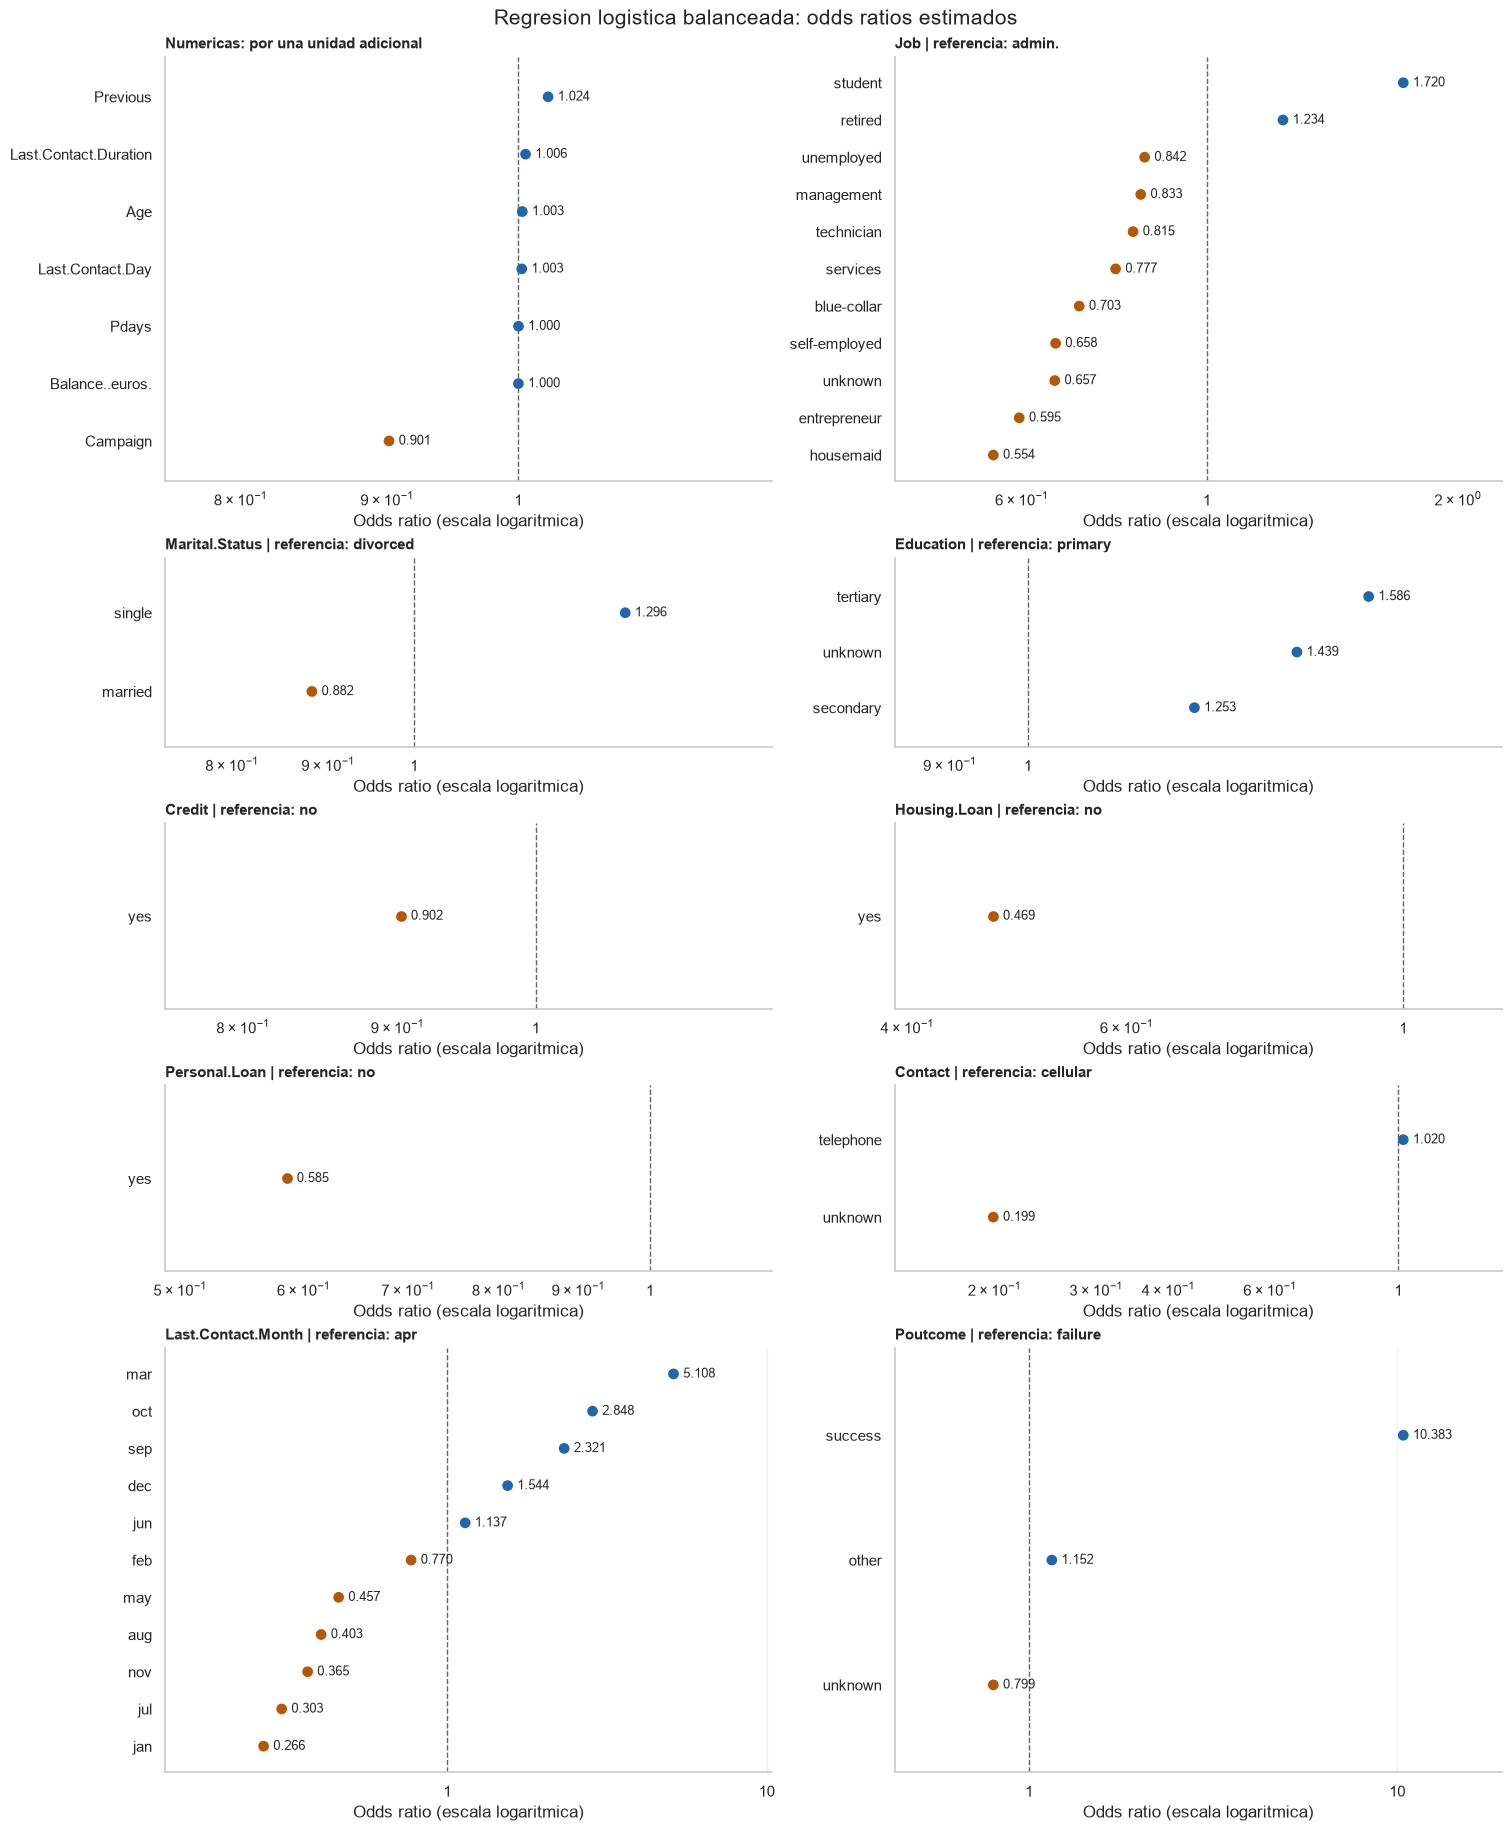

In [ ]:
from matplotlib.ticker import FuncFormatter
import math

# Usar los parametros ya estimados; no se reajusta el modelo.
paneles_or = []
numericos_or = tabla_parametros_originales[
    tabla_parametros_originales['Termino'].isin(numeric_cols)
].copy()
if not numericos_or.empty:
    paneles_or.append(('Numericas: por una unidad adicional', numericos_or))
for referencia_or in referencias_categoricas:
    variable_or = referencia_or['Variable']
    grupo_or = tabla_parametros_originales[
        tabla_parametros_originales['Termino'].str.startswith(variable_or + '=')
    ].copy()
    if not grupo_or.empty:
        grupo_or['Termino'] = grupo_or['Termino'].str.slice(len(variable_or) + 1)
        paneles_or.append((f"{variable_or} | referencia: {referencia_or['Referencia']}", grupo_or))

columnas_or = 2
filas_or = math.ceil(len(paneles_or) / columnas_or)
alturas_or = [max(2.4, 0.38 * max(len(datos) for _, datos in paneles_or[i:i + columnas_or]) + 1.3)
              for i in range(0, len(paneles_or), columnas_or)]
fig_or, axes_or = plt.subplots(
    filas_or, columnas_or, figsize=(15, sum(alturas_or)), squeeze=False,
    gridspec_kw={'height_ratios': alturas_or}, layout='constrained'
)
for ax_or, (titulo_or, datos_or) in zip(axes_or.flat, paneles_or):
    datos_or = datos_or.sort_values('Odds ratio')
    valores_or = datos_or['Odds ratio'].to_numpy()
    posiciones_or = np.arange(len(datos_or))
    colores_or = np.where(valores_or >= 1, '#2166ac', '#b35806')
    ax_or.axvline(1, color='#666666', linestyle='--', linewidth=1)
    ax_or.scatter(valores_or, posiciones_or, c=colores_or, s=45, zorder=3)
    ax_or.set_yticks(posiciones_or, labels=datos_or['Termino'])
    ax_or.set_xscale('log')
    # Incluir siempre OR=1 y dejar espacio para las etiquetas numericas.
    inferior_or = min(float(valores_or.min()), 1.0)
    superior_or = max(float(valores_or.max()), 1.0)
    margen_or = max(np.log(superior_or / inferior_or) * 0.24, 0.18)
    ax_or.set_xlim(inferior_or * np.exp(-margen_or), superior_or * np.exp(margen_or))
    for valor_or, posicion_or in zip(valores_or, posiciones_or):
        ax_or.annotate(f'{valor_or:.3f}', (valor_or, posicion_or),
                       xytext=(7, 0), textcoords='offset points', va='center', fontsize=9)
    ax_or.xaxis.set_major_formatter(FuncFormatter(lambda valor, _: f'{valor:g}'))
    ax_or.set_title(titulo_or, loc='left', fontsize=11, fontweight='bold')
    ax_or.set_xlabel('Odds ratio (escala logaritmica)')
    ax_or.grid(axis='x', alpha=0.25)
    ax_or.grid(axis='y', visible=False)
    ax_or.set_ylim(-0.7, len(datos_or) - 0.3)
    ax_or.spines[['top', 'right']].set_visible(False)
for ax_or in list(axes_or.flat)[len(paneles_or):]:
    ax_or.set_visible(False)
fig_or.suptitle('Regresion logistica balanceada: odds ratios estimados', fontsize=15)
plt.show()


**Resumen:**
Para esta sección se estimaron los parámetros de la regresión logística balanceada con las 31.648 observaciones de entrenamiento. El ajuste convergió en 6 iteraciones y produjo 51 coeficientes y un intercepto, mediante log-verosimilitud ponderada con penalización L2. Se expresaron los efectos numéricos en unidades originales y los efectos categóricos frente a sus referencias, con sus correspondientes odds ratios. Por ultimo, se verificó que la ecuación reconstruida reproduce las probabilidades del pipeline. Esta comprobación valida el cálculo de los parámetros; la capacidad predictiva fuera del ajuste se sustenta en la validación cruzada de la sección 1.
